## Praktikum 3
##### PyTorch

In diesem Praktikum betrachten wir PyTorch und seine Architektur. Wir nutzen dies, um einige Convoluted Neural Networks (CNNs) zu trainieren.

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526_PyTorch</b>
</div>

In [3]:
# imports
import torch
import torch.nn.functional as F
from torch.nn import CrossEntropyLoss, Softmax, LazyLinear, Dropout, LazyBatchNorm1d, ReLU, Sequential
from torch.utils.data import DataLoader
from torch.optim import RMSprop, Adam, SGD
from torch.optim.lr_scheduler import ReduceLROnPlateau

from torchvision.datasets import ImageFolder
from torchvision.transforms import PILToTensor, v2, ToTensor
from torchvision.transforms.functional import to_pil_image
from torchvision.models import efficientnet_b7

import os
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import tqdm
from random import sample

import utils.torch_utils as tUtils

In [4]:
# Haben Wirkung auf Genauigkeit und Performance
BATCH_SIZE = 8
EPOCHS = 15

# Diese Werte sollen nicht geändert werden
NUM_WORKERS = 0  # Muss 0 im Notebook bleiben, da es sonst crasht
SEED = 21
ROOT = './data/mini_dataset'
MODEL_SAVE_PATH = './data/models/apparel-classification-mini-dataset-EfNetB7_15Epochs.pt'

# Klassen
CLASSES = ['Dress', 'Pants', 'Shirt', 'Shoes', 'Shorts']
N_CLASSES = len(CLASSES)

# Torch-Seed setzen
torch.manual_seed(SEED)

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.1:</b><br>
  • Setzen Sie, wie in Aufgabe 1.1, das Ausführungsdevice so, dass PyTorch über CUDA trainiert, falls es verfügbar ist. Ansonsten soll die CPU verwendet werden.<br>
  • Geben Sie aus, welches Ausführungsdevice Ihr System verwendet.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Falls Sie CUDA verwenden, das Netzwerk aber beim Trainieren Fehler wirft (und Sie Torch richtig installiert haben), können Sie alternativ über die CPU trainieren.<br>
Das ist nur deutlich langsamer.
</div>

In [5]:
# Ausführungs-Device ändern
device = "cuda"

print("Ausführungs-Device: " + str(device))

Ausführungs-Device: cuda


In [6]:
# Transformer und Augmenter erstellen
transform = v2.Compose([
    ToTensor(),
    v2.Resize((224, 224), interpolation=v2.InterpolationMode.BILINEAR),
])

transform_and_augment = v2.Compose([
    ToTensor(),
    v2.Resize((224, 224), interpolation=v2.InterpolationMode.BILINEAR),
    v2.RandomAffine(degrees=15, translate=(0.1, 0.1), fill = 1),
    v2.RandomHorizontalFlip(),
])

In [7]:
# Datenset aufbereiten
train_dataset = ImageFolder(root = os.path.join(ROOT, 'train'), transform=transform_and_augment)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

val_dataset = ImageFolder(root = os.path.join(ROOT, 'val'), transform=transform)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

test_dataset = ImageFolder(root = os.path.join(ROOT, 'test'), transform=transform)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)

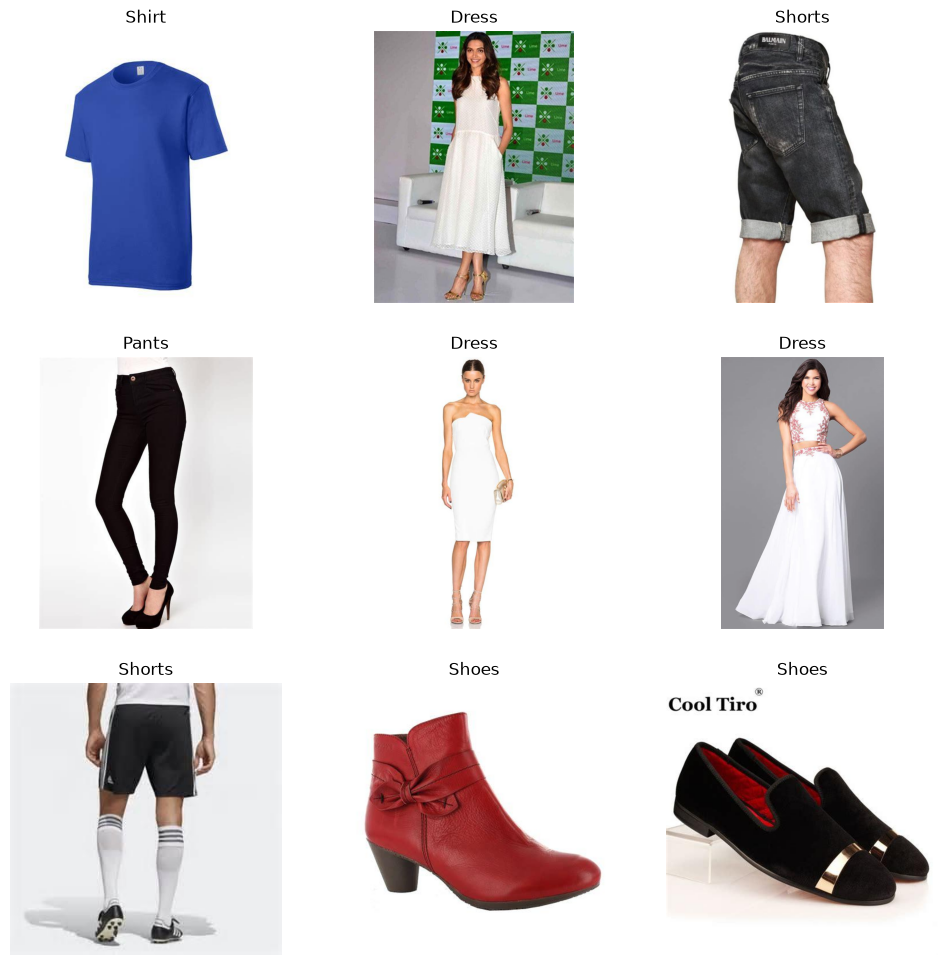

In [9]:
# Beispiele anzeigen
fig = plt.figure(figsize = (12, 12))
for i, idx in enumerate(sample(range(len(train_dataset)), 9)):
  pil_img = train_dataset.loader(train_dataset.imgs[idx][0])
  img = ToTensor()(pil_img)
  label = train_dataset.targets[idx]

  plt.subplot(330 + 1 + i)
  plt.axis('off')
  plt.imshow(to_pil_image(img))
  plt.title(CLASSES[label])

plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.2:</b><br>
  • Laden Sie das <code>efficientnet_b7</code> mit Standardgewichten.<br>
  • Setzen Sie das Modell auf das richtige Ausführungsdevice.<br>
  • Trainieren Sie das Modell mit dem gegebenen Classifier und schauen Sie sich die Loss- und Accuracy-Kurven an.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Falls das Training länger dauert als üblich, starten Sie Visual Studio Code neu.
</div>

In [18]:
from torchvision.models import EfficientNet_B7_Weights
image_model = efficientnet_b7(weights=EfficientNet_B7_Weights.DEFAULT)

image_model.classifier = Sequential(
    LazyLinear(1024),
    ReLU(),
    Dropout(p=0.5),
    LazyLinear(512),
    ReLU(),
    LazyLinear(64),
    ReLU(),
    LazyBatchNorm1d(),
    LazyLinear(16),
    ReLU(),
    LazyLinear(N_CLASSES)
)

# Auf Ausführungsdevice setzen
image_model = image_model.to(device)
print(image_model)

optimizer = Adam(image_model.parameters(), lr=0.0001, eps=1e-7)
criterion = CrossEntropyLoss()

scheduler = ReduceLROnPlateau(optimizer, 
                              'min', 
                              factor=0.1, 
                              patience=6, 
                              eps=5*1e-3, 
                              min_lr=5*1e-9)

Downloading: "https://download.pytorch.org/models/efficientnet_b7_lukemelas-c5b4e57e.pth" to C:\Users\David/.cache\torch\hub\checkpoints\efficientnet_b7_lukemelas-c5b4e57e.pth


100%|██████████| 255M/255M [00:27<00:00, 9.79MB/s] 


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
            (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(64, 16, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
      

In [19]:
history = tUtils.train2(model=image_model, 
                epochs=EPOCHS, 
                optimizer=optimizer, 
                criterion=criterion, 
                train_loader=train_loader, 
                val_loader=val_loader, 
                device=device, 
                scheduler=scheduler, 
                save_best_path=MODEL_SAVE_PATH)

  - eval: 100%|██████████| 19/19 [00:01<00:00, 15.77it/s, loss=1.44, accuracy=0.433, val_loss=1.38, val_accuracy=0.586]


Saved best model with val_acc=0.5855 to ./data/models/apparel-classification-mini-dataset-EfNetB7_15Epochs.pt



  - eval: 100%|██████████| 19/19 [00:01<00:00, 15.89it/s, loss=1.07, accuracy=0.768, val_loss=0.983, val_accuracy=0.912]


Saved best model with val_acc=0.9123 to ./data/models/apparel-classification-mini-dataset-EfNetB7_15Epochs.pt



  - eval: 100%|██████████| 19/19 [00:01<00:00, 16.79it/s, loss=0.871, accuracy=0.867, val_loss=0.799, val_accuracy=0.965]


Saved best model with val_acc=0.9649 to ./data/models/apparel-classification-mini-dataset-EfNetB7_15Epochs.pt



... (10 outputs left out)

  - eval: 100%|██████████| 19/19 [00:01<00:00, 14.97it/s, loss=0.262, accuracy=0.954, val_loss=0.21, val_accuracy=0.974] 


  - eval: 100%|██████████| 19/19 [00:01<00:00, 14.05it/s, loss=0.23, accuracy=0.964, val_loss=0.207, val_accuracy=0.974]


  - eval: 100%|██████████| 19/19 [00:01<00:00, 14.78it/s, loss=0.206, accuracy=0.96, val_loss=0.199, val_accuracy=0.961]


  - eval: 100%|██████████| 19/19 [00:01<00:00, 15.25it/s, loss=0.2, accuracy=0.97, val_loss=0.164, val_accuracy=0.967]

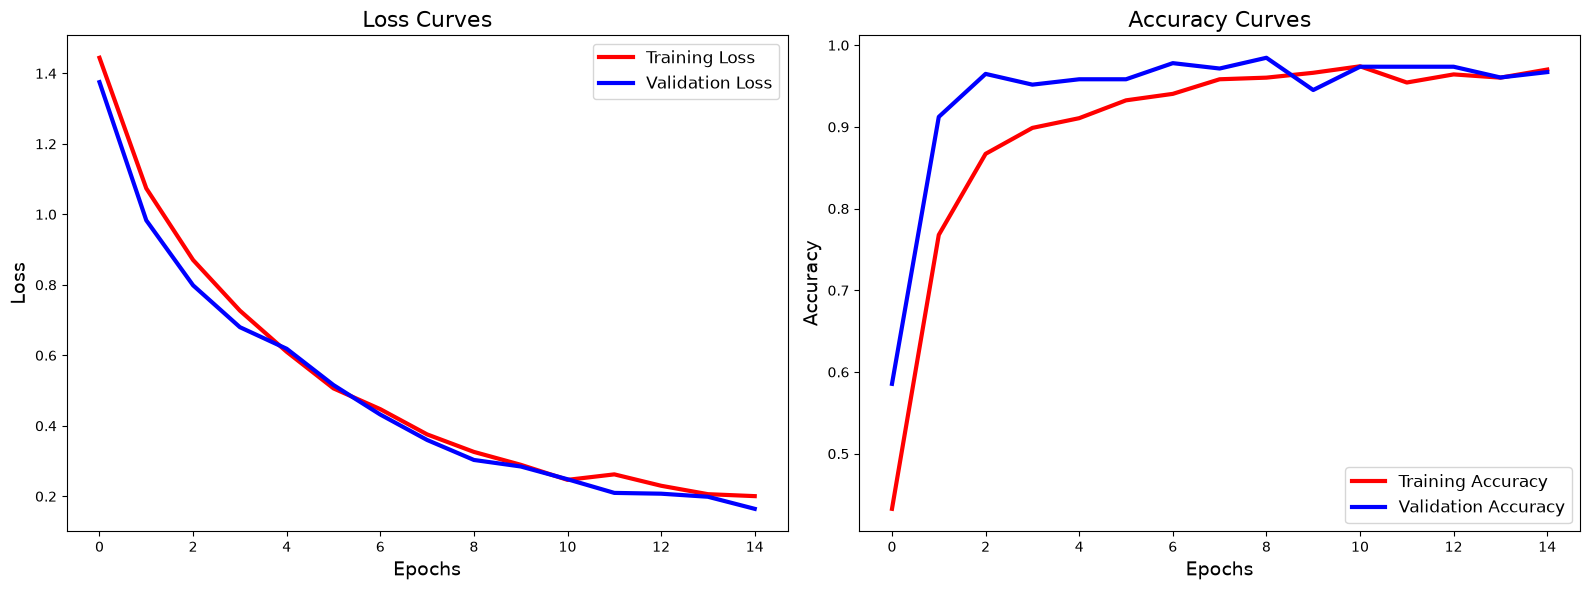

In [20]:
# Kurven Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(16,6))

axes[0].plot(history['loss'], 'r', linewidth=3.0)
axes[0].plot(history['val_loss'], 'b', linewidth=3.0)
axes[0].set_title('Loss Curves', fontsize=16)
axes[0].set_xlabel('Epochs', fontsize=14)
axes[0].set_ylabel('Loss', fontsize=14)
axes[0].legend(['Training Loss', 'Validation Loss'], fontsize=12)

axes[1].plot(history['accuracy'], 'r', linewidth=3.0)
axes[1].plot(history['val_accuracy'], 'b', linewidth=3.0)
axes[1].set_title('Accuracy Curves', fontsize=16)
axes[1].set_xlabel('Epochs', fontsize=14)
axes[1].set_ylabel('Accuracy', fontsize=14)
axes[1].legend(['Training Accuracy', 'Validation Accuracy'], fontsize=12)

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.3:</b><br>
  • Evaluieren Sie das Model, indem Sie den Klassifizierungs-Report ausgeben.<br>
  • Zeichnen Sie die Konfusions-Matrix.<br>
  • Testen Sie das Netzwerk auf den Bildern <code>data/test_images/test-image-1.jpg</code> bis <code>data/test_images/test-image-5.jpg</code> mit Hilfe der entsprechenden Methode aus <code>tUtils</code>.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Schauen Sie sich die Imports dieses Notebooks genauer an.
</div>

In [21]:
predictions = []
targets = []

with tqdm.tqdm(enumerate(test_loader), total=len(test_loader)) as bar:
    bar.set_description(f"Evaluation")

    image_model.eval()
    with torch.no_grad():
        for i, data in bar:
            inputs, labels = data

            if device is not None:
                inputs, labels = inputs.to(device=device), labels.to(device=device)

            outputs = image_model(inputs)

            predictions.append(outputs.squeeze().argmax().item())
            targets.append(labels.item())


Evaluation: 100%|██████████| 1163/1163 [00:45<00:00, 25.73it/s]


              precision    recall  f1-score   support

       Dress       0.97      0.85      0.91       268
       Pants       0.92      0.93      0.92       290
       Shirt       0.80      0.99      0.89       169
       Shoes       1.00      0.92      0.96       343
      Shorts       0.81      0.97      0.88        93

    accuracy                           0.92      1163
   macro avg       0.90      0.93      0.91      1163
weighted avg       0.93      0.92      0.92      1163



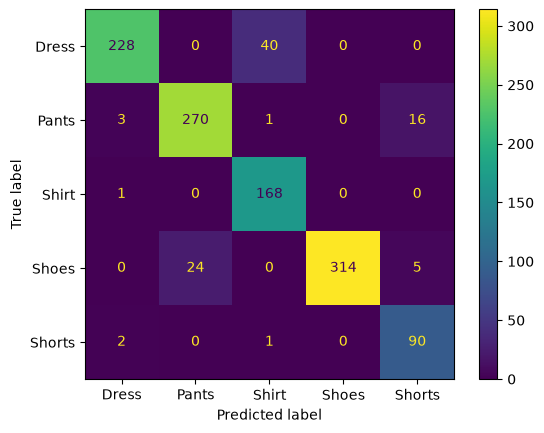

In [22]:
# Klassifizierungs-Report
print(classification_report(targets,predictions,target_names=CLASSES))

# Konfusionsmatrix
cm = confusion_matrix(targets,predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)

disp = disp.plot(include_values = True,
                 values_format = 'd',
                 cmap = 'viridis',
                 ax = None,
                 xticks_rotation = 'horizontal')

plt.show()

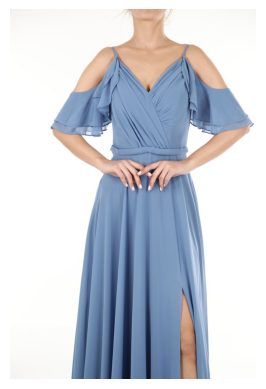

This image is a Shirt with a 64.28% confidence.


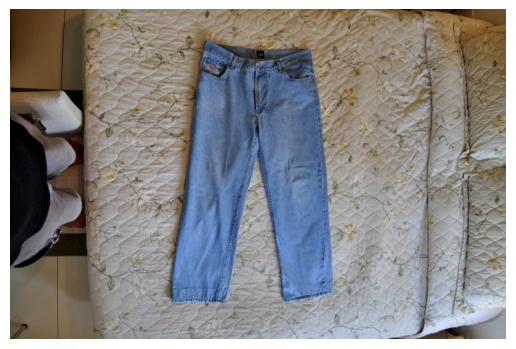

This image is a Shorts with a 39.42% confidence.


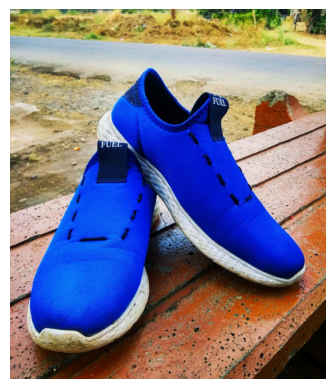

This image is a Shoes with a 92.18% confidence.


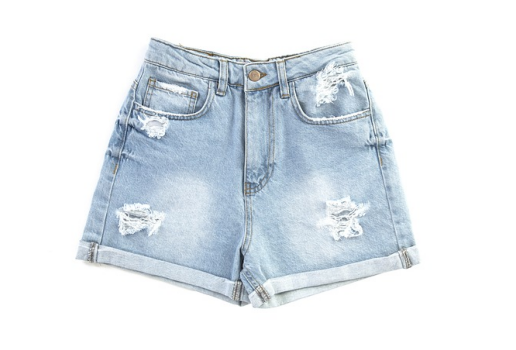

This image is a Shorts with a 82.21% confidence.


In [23]:
# Testbilder
for i in range(1,5):
    tUtils.test(f"data/test_images/test-image-{i}.jpg", transform,device,image_model,CLASSES)